# Card 26 - Métricas e validação de modelos

Replica os exemplos das aulas no dataset Breast Cancer (sklearn): matriz de confusão, precisão/recall,
curva ROC, efeito do *cutoff*, árvore vs random forest e SHAP num `LinearSVC`.

> Com as seeds fixas, as métricas dos modelos dão sempre o mesmo resultado. Os valores do SHAP variam
> um pouco na 3ª casa decimal se você tirar o `np.random.seed`, porque o `KernelExplainer` sorteia combinações de variáveis.

In [2]:
!pip install scikit-learn shap pandas matplotlib

  Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached pandas-3.0.6-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn import metrics
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)  # o KernelExplainer do shap usa o sorteio global do numpy

/home/edryck/Documentos/BootCamp/III - Aprendizado de Máquina Aplicado/Card 26 - Métricas e Validação de Modelos de Aprendizado de Máquina /Pratica/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dados

No dataset original 0 = maligno e 1 = benigno. O evento que interessa é o maligno, então eu inverto: assim o *recall* passa a medir "quantos tumores malignos eu peguei".

In [16]:
data = load_breast_cancer()
X = data.data
y = 1 - data.target   # 1 = maligno (evento de interesse), 0 = benigno

# stratify mantém a mesma proporção de malignos no treino e no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("treino:", X_train.shape, "| teste:", X_test.shape)
print("proporção de malignos no teste: %.3f" % y_test.mean())

treino: (455, 30) | teste: (114, 30)
proporção de malignos no teste: 0.368


## Métricas a partir da matriz de confusão

Uma função só: dado o rótulo verdadeiro, a probabilidade e o corte, devolve a matriz e as 4 métricas.

In [20]:
def summarize(y_true, prob, cutoff=0.5):
    pred = (prob >= cutoff).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, pred).ravel()
    return {
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "precision": tp / (tp + fp) if (tp + fp) else float("nan"),   # do que eu previ, quanto era de fato
        "recall": tp / (tp + fn),            # do que existia, quanto eu peguei
        "specificity": tn / (tn + fp),       # o recall da outra classe
    }

## Árvore sem limite vs random forest

A árvore sem limite de profundidade é a candidata a decorar o treino. A forest usa 350 árvores com `min_samples_leaf=5`.

In [23]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
forest = RandomForestClassifier(
    n_estimators=350, min_samples_leaf=5, n_jobs=-1, random_state=SEED
).fit(X_train, y_train)

models = {"decision_tree": tree, "random_forest": forest}
rows = {}
for name, model in models.items():
    p_train = model.predict_proba(X_train)[:, 1]
    p_test = model.predict_proba(X_test)[:, 1]
    row = summarize(y_test, p_test)
    row["auc_train"] = metrics.roc_auc_score(y_train, p_train)
    row["auc_test"] = metrics.roc_auc_score(y_test, p_test)
    # validação cruzada: com só 114 exemplos de teste, uma divisão sozinha pode enganar
    row["auc_cv5"] = cross_val_score(model, X, y, cv=5, scoring="roc_auc").mean()
    rows[name] = row

pd.DataFrame(rows).round(3)

,decision_tree,random_forest
TN,68.000,72.000
FP,4.000,0.000
FN,4.000,3.000
TP,38.000,39.000
accuracy,0.930,0.974
precision,0.905,1.000
recall,0.905,0.929
specificity,0.944,1.000
auc_train,1.000,0.998
auc_test,0.925,0.994


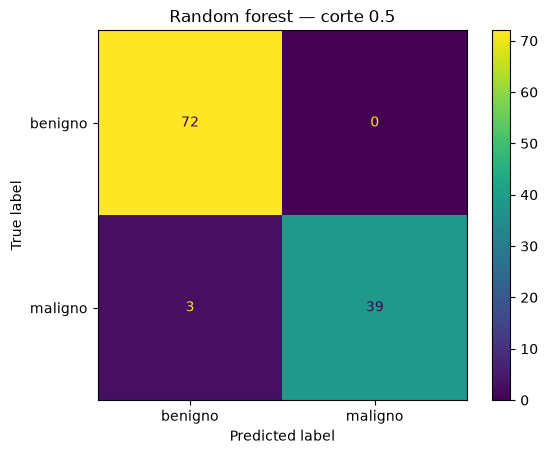

In [26]:
# matriz de confusão da forest no corte 0.5
p_forest = forest.predict_proba(X_test)[:, 1]
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, (p_forest >= 0.5).astype(int), display_labels=["benigno", "maligno"]
)
plt.title("Random forest — corte 0.5")
plt.show()

## Mexendo só no cutoff

O modelo é o mesmo (nada é retreinado). Só muda onde eu corto a probabilidade.

In [27]:
cutoffs = [0.1, 0.3, 0.5, 0.7, 0.9]
pd.DataFrame({c: summarize(y_test, p_forest, c) for c in cutoffs}).T.round(3)

,TN,FP,FN,TP,accuracy,precision,recall,specificity
0.1,58.0,14.0,0.0,42.0,0.877,0.750,1.000,0.806
0.3,70.0,2.0,3.0,39.0,0.956,0.951,0.929,0.972
0.5,72.0,0.0,3.0,39.0,0.974,1.000,0.929,1.000
0.7,72.0,0.0,7.0,35.0,0.939,1.000,0.833,1.000
0.9,72.0,0.0,17.0,25.0,0.851,1.000,0.595,1.000


## Curva ROC

A ROC varre todos os cortes: eixo Y = sensibilidade (recall), eixo X = 1 − especificidade.

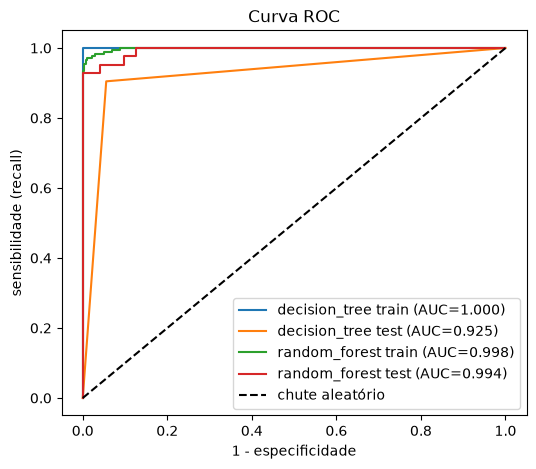

In [30]:
plt.figure(figsize=(6, 5))
for name, model in models.items():
    for split, (X_s, y_s) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        prob = model.predict_proba(X_s)[:, 1]
        fpr, tpr, thresholds = metrics.roc_curve(y_s, prob)   # os 3 vetores: fpr, tpr e cada corte
        auc = metrics.roc_auc_score(y_s, prob)
        plt.plot(fpr, tpr, label="%s %s (AUC=%.3f)" % (name, split, auc))

plt.plot([0, 1], [0, 1], "k--", label="chute aleatório")
plt.xlabel("1 - especificidade")
plt.ylabel("sensibilidade (recall)")
plt.title("Curva ROC")
plt.legend()
plt.show()

## SHAP num modelo que não se explica sozinho

O `LinearSVC` só devolve a classe (ou a distância até a fronteira). O `KernelExplainer` funciona com qualquer modelo;
o `shap.kmeans` resume o treino em 10 centróides para acelerar. Explico a `decision_function` (contínua) em vez do `predict` (0/1), que dá valores bem mais grosseiros.

In [34]:
svc = LinearSVC(max_iter=20000, random_state=SEED).fit(X_train, y_train)
print("acurácia do SVC no teste: %.3f" % svc.score(X_test, y_test))

background = shap.kmeans(X_train, 10)
explainer = shap.KernelExplainer(svc.decision_function, background)

sample = X_test[:40]   # 40 exemplos pra não demorar
shap_values = explainer.shap_values(sample, silent=True)

acurácia do SVC no teste: 0.930


/tmp/ipykernel_2413585/1311946378.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample, feature_names=data.feature_names)


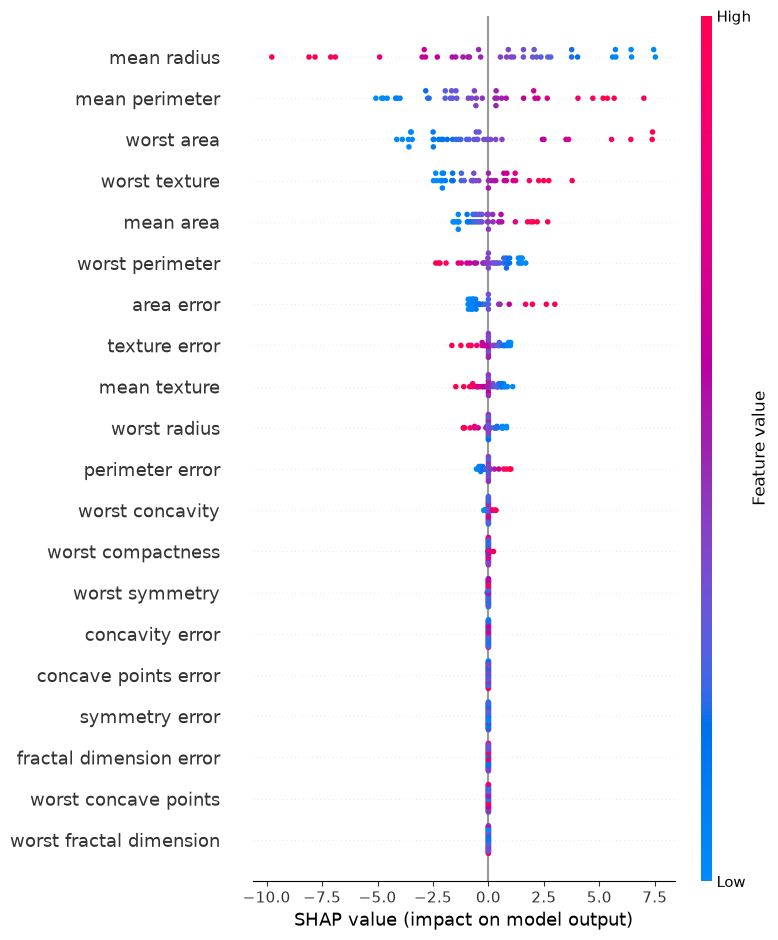

In [37]:
# visão global: quais variáveis mais pesam e em que direção (cor = valor da variável)
shap.summary_plot(shap_values, sample, feature_names=data.feature_names)

In [40]:
# importância = média do valor absoluto do SHAP por variável
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=data.feature_names)
importance.sort_values(ascending=False).head(10)

mean radius        3.514030
mean perimeter     2.512919
worst area         2.351889
worst texture      1.357299
mean area          0.848820
worst perimeter    0.847772
area error         0.719842
texture error      0.493347
mean texture       0.456416
worst radius       0.301735
dtype: float64

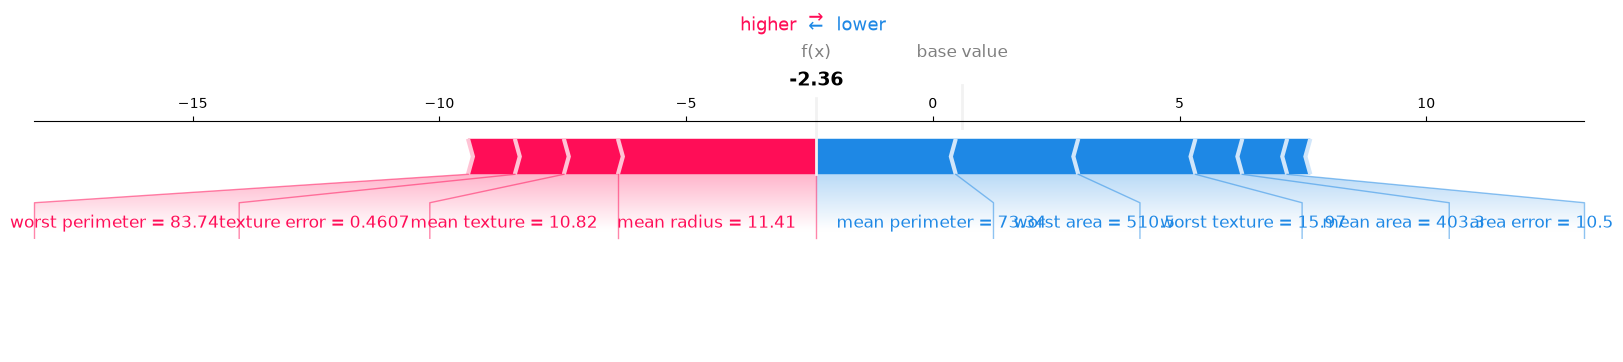

In [45]:
# visão individual: como cada variável empurrou a predição do exemplo 0
shap.force_plot(
    explainer.expected_value, shap_values[0], sample[0],
    feature_names=data.feature_names, matplotlib=True,
)

### Conferindo o SHAP

1. **Aditividade:** valor base + soma das contribuições tem que dar a saída do modelo.
2. **Coeficientes:** como o SVM é linear, o ranking do SHAP tem que bater com `|coef| × desvio-padrão`.

In [51]:
base = float(np.ravel(explainer.expected_value)[0])
print("base + soma dos SHAP: %.4f" % (base + shap_values[0].sum()))
print("saída real do modelo : %.4f" % svc.decision_function(sample[:1])[0])

weight = pd.Series(np.abs(svc.coef_[0]) * X_train.std(axis=0), index=data.feature_names)
print("\ntop 5 pelo SHAP     :", list(importance.sort_values(ascending=False).head(5).index))
print("top 5 pelos coefs   :", list(weight.sort_values(ascending=False).head(5).index))

base + soma dos SHAP: -2.3615
saída real do modelo : -2.3615

top 5 pelo SHAP     : ['mean radius', 'mean perimeter', 'worst area', 'worst texture', 'mean area']
top 5 pelos coefs   : ['mean radius', 'worst area', 'mean perimeter', 'area error', 'worst texture']
